## 2. Analyse exploratoire et visualisation

### Objectif

L’objectif de cette partie est de comprendre la structure et les dynamiques des données relatives aux combats de lutte sénégalaise (lamb).  
Il s’agit d’identifier les tendances principales, d’analyser les performances économiques et de mettre en évidence les facteurs clés de génération de revenus.

Cette analyse permet de répondre à des questions essentielles telles que :
- Quel est le chiffre d’affaires total généré ?
- Comment évoluent les revenus dans le temps ?
- Quels lutteurs génèrent le plus de revenus ?
- Quelles arènes sont les plus rentables ?
- Quelle est la distribution des revenus des combats ?

---

### Approche

Dans un premier temps, une analyse exploratoire est réalisée à l’aide d’agrégations sur les données afin de dégager des indicateurs clés.

Dans un second temps, des visualisations sont produites afin de représenter graphiquement ces résultats et faciliter leur interprétation.

---

### Indicateurs analysés

Les principaux indicateurs étudiés sont :

- Le chiffre d’affaires total
- L’évolution du chiffre d’affaires dans le temps
- Le classement des lutteurs selon les revenus générés
- Les revenus par arène
- La distribution des revenus des combats

---

### Visualisations

Afin de rendre les résultats plus lisibles et interprétables, plusieurs graphiques sont réalisés :

1. Évolution du chiffre d’affaires (graphique en ligne)
2. Top des lutteurs par revenu (diagramme en barres)
3. Revenus par arène (diagramme en barres)
4. Distribution des revenus (histogramme)
5. Nombre de tickets vendus par combat (diagramme en barres)

Ces visualisations permettent d’identifier les tendances majeures et de mieux comprendre la structure économique du lamb.

In [ ]:
df_clean.printSchema()
df_clean.show(5)

root
 |-- fight_id: integer (nullable = true)
 |-- date: date (nullable = true)
 |-- wrestler_1: integer (nullable = true)
 |-- wrestler_2: integer (nullable = true)
 |-- winner: integer (nullable = true)
 |-- revenue: float (nullable = true)
 |-- tickets_sold: integer (nullable = true)
 |-- sponsor_revenue: long (nullable = true)
 |-- arena: string (nullable = true)
 |-- promoter: string (nullable = true)
 |-- winner_label: string (nullable = true)
 |-- total_revenue: double (nullable = true)
 |-- has_ticket_revenue: boolean (nullable = false)
 |-- year: integer (nullable = true)
 |-- month: integer (nullable = true)
 |-- revenue_per_ticket: double (nullable = true)

+--------+----------+----------+----------+------+-----------+------------+---------------+----------------+-----------------+------------+-------------+------------------+----+-----+------------------+
|fight_id|      date|wrestler_1|wrestler_2|winner|    revenue|tickets_sold|sponsor_revenue|           arena|         pro

Partie 1: Le chiffre d'Affaire et son évolution

On calcule le chiffre d’affaires total pour mesurer la taille économique globale du secteur du lamb. Cela permet d’avoir une première vision de l’importance financière des combats analysés.

In [ ]:
from pyspark.sql.functions import sum

df_clean.agg(
    sum("total_revenue").alias("chiffre_affaires_total")
).show()

+----------------------+
|chiffre_affaires_total|
+----------------------+
|       2.1991837206E10|
+----------------------+



Le chiffre d’affaires total est d’environ 22 milliards, ce qui montre que le secteur du lamb génère des revenus importants

Visualisation1: Evolution du chiffre d'affaire dans le temps



In [ ]:
ca_time = df_clean.groupBy("year", "month") \
    .agg(sum("total_revenue").alias("revenue")) \
    .orderBy("year", "month")

ca_time.show()

+----+-----+------------+
|year|month|     revenue|
+----+-----+------------+
|2022|    1|8.65270086E8|
|2022|    2|4.40948205E8|
|2022|    3|6.75983775E8|
|2022|    4|8.43685724E8|
|2022|    5|7.16323431E8|
|2022|    6|8.01169895E8|
|2022|    7|8.16570852E8|
|2022|    8|7.46003476E8|
|2022|    9|8.95557815E8|
|2022|   10|7.78703168E8|
|2022|   11|9.30180141E8|
|2022|   12|5.43085316E8|
|2023|    1| 6.2151536E8|
|2023|    2|9.05199859E8|
|2023|    3|4.76925202E8|
|2023|    4|6.77262153E8|
|2023|    5|7.29460226E8|
|2023|    6|6.63489154E8|
|2023|    7|6.39769943E8|
|2023|    8|6.18928714E8|
+----+-----+------------+
only showing top 20 rows


In [ ]:
pdf = ca_time.toPandas()
pdf.head()

,year,month,revenue
0,2022,1,865270086.0
1,2022,2,440948205.0
2,2022,3,675983775.0
3,2022,4,843685724.0
4,2022,5,716323431.0


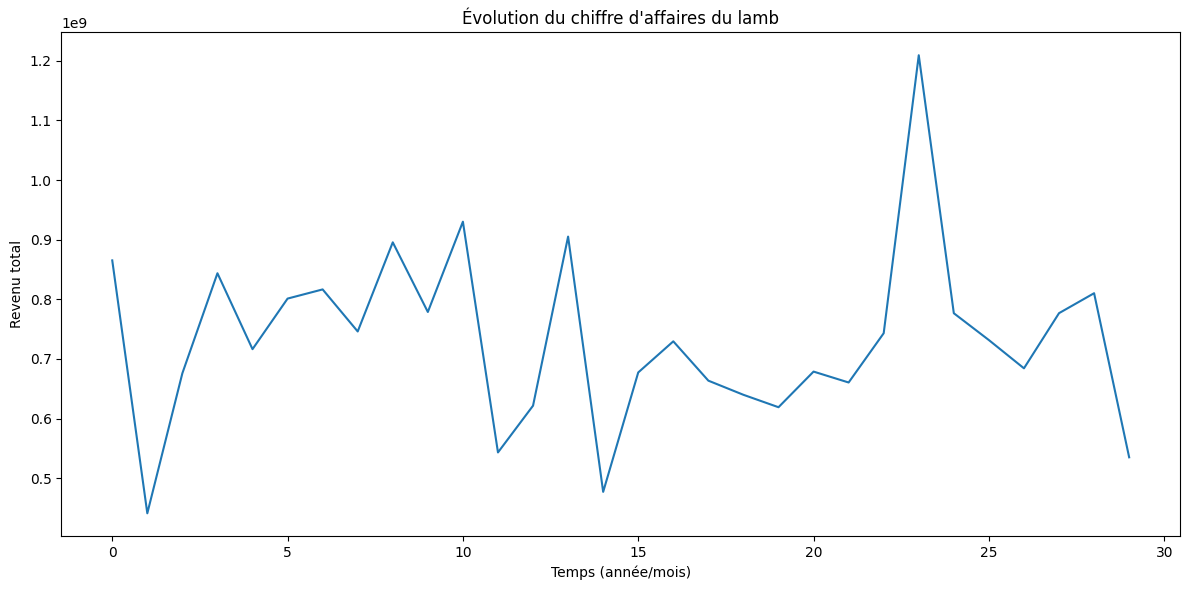

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.plot(range(len(pdf)), pdf["revenue"])
plt.title("Évolution du chiffre d'affaires du lamb")
plt.xlabel("Temps (année/mois)")
plt.ylabel("Revenu total")
plt.tight_layout()
plt.savefig("graph1_ca.png", dpi=300)
plt.show()
from google.colab import files
files.download("graph1_ca.png")

Les fortes variations montrent une dépendance à quelques événements clés, ce qui traduit une concentration de l’activité économique autour des combats les plus importants.

Partie 2: Top Lutteurs

On veut identifier les lutteurs qui génèrent le plus de revenus.
 Cela permet de voir si l’économie du lamb est dominée par quelques figures importantes.

Dictionnaire des lutteurs

In [40]:
wrestler_names = {
    0: "Balla Gaye 2",
    1: "Modou Lo",
    2: "Eumeu Sène",
    3: "Bombardier",
    4: "Lac 2",
    5: "Gris Bordeaux",
    6: "Tapha Tine",
    7: "Ama Baldé",
    8: "Boy Niang 2",
    9: "Reug Reug",
    10: "Sa Thiès",
    11: "Gouye Gui",
    12: "Zarco",
    13: "Papa Sow",
    14: "Forza",
    15: "Less 2"
}

In [46]:
df_lutteurs = df_clean.filter(col("winner").isNotNull())

In [47]:
from pyspark.sql.functions import col, when, create_map, lit
from itertools import chain

mapping_expr = create_map([lit(x) for x in chain(*wrestler_names.items())])

df_clean = df_clean.withColumn(
    "winner_name",
    when(col("winner").isNull(), "Nul/Annulé")
    .otherwise(mapping_expr[col("winner")])
)

df_clean.select("winner", "winner_name").show(10, truncate=False)

+------+-----------+
|winner|winner_name|
+------+-----------+
|NULL  |Nul/Annulé |
|15    |Less 2     |
|9     |Reug Reug  |
|14    |Forza      |
|6     |Tapha Tine |
|NULL  |Nul/Annulé |
|8     |Boy Niang 2|
|3     |Bombardier |
|NULL  |Nul/Annulé |
|NULL  |Nul/Annulé |
+------+-----------+
only showing top 10 rows


In [48]:
from pyspark.sql.functions import sum, desc

top_lutteurs = df_clean.groupBy("winner_name") \
    .agg(sum("total_revenue").alias("revenu_total")) \
    .orderBy(desc("revenu_total")) \
    .limit(10)

top_lutteurs.show(truncate=False)

+-------------+-------------+
|winner_name  |revenu_total |
+-------------+-------------+
|Nul/Annulé   |7.052169791E9|
|Bombardier   |1.502953557E9|
|Sa Thiès     |1.162039833E9|
|Modou Lo     |1.09233031E9 |
|Reug Reug    |1.046644948E9|
|Papa Sow     |1.033706636E9|
|Ama Baldé    |9.78712432E8 |
|Zarco        |9.54993978E8 |
|Boy Niang 2  |9.29511311E8 |
|Gris Bordeaux|9.16579543E8 |
+-------------+-------------+



In [52]:
from pyspark.sql.functions import sum, desc

top_lutteurs = df_lutteurs.groupBy("winner_name") \
    .agg(sum("total_revenue").alias("revenu_total")) \
    .orderBy(desc("revenu_total")) \
    .limit(10)

top_lutteurs.show(truncate=False)

+-------------+-------------+
|winner_name  |revenu_total |
+-------------+-------------+
|Bombardier   |1.502953557E9|
|Sa Thiès     |1.162039833E9|
|Modou Lo     |1.09233031E9 |
|Reug Reug    |1.046644948E9|
|Papa Sow     |1.033706636E9|
|Ama Baldé    |9.78712432E8 |
|Zarco        |9.54993978E8 |
|Boy Niang 2  |9.29511311E8 |
|Gris Bordeaux|9.16579543E8 |
|Tapha Tine   |8.83202578E8 |
+-------------+-------------+



In [53]:
pdf_top_lutteurs = top_lutteurs.toPandas()
pdf_top_lutteurs

,winner_name,revenu_total
0,Bombardier,1.502954e+09
1,Sa Thiès,1.162040e+09
2,Modou Lo,1.092330e+09
3,Reug Reug,1.046645e+09
4,Papa Sow,1.033707e+09
5,Ama Baldé,9.787124e+08
6,Zarco,9.549940e+08
7,Boy Niang 2,9.295113e+08
8,Gris Bordeaux,9.165795e+08
9,Tapha Tine,8.832026e+08


Visualisation 2: Top Lutteur

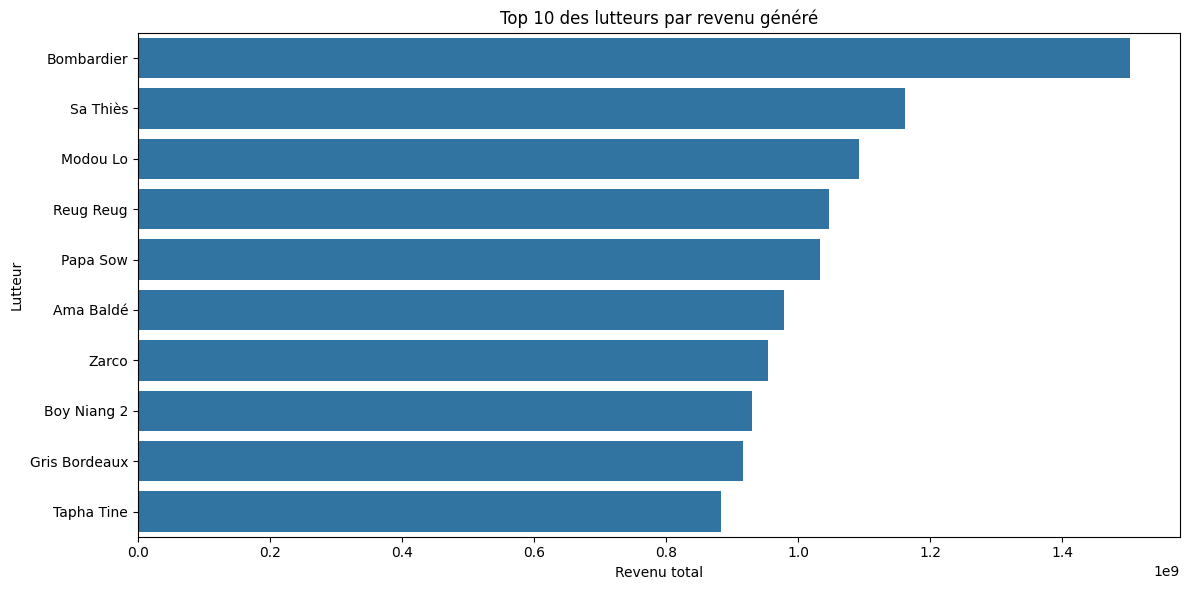

In [54]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.barplot(data=pdf_top_lutteurs, x="revenu_total", y="winner_name")
plt.title("Top 10 des lutteurs par revenu généré")
plt.xlabel("Revenu total")
plt.ylabel("Lutteur")
plt.tight_layout()
plt.savefig("graph2_lutteurs_noms.png", dpi=300)
plt.show()

In [55]:
from google.colab import files
files.download("graph2_lutteurs_noms.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Selon notre analyse, Bombardier est le lutteur qui génère le plus de revenus, suivi de Sa Thiès. Cela montre que certaines figures dominent économiquement le secteur, même si cela ne reflète pas forcément le classement sportif réel.”

Partie 3: Revenu par Arène

In [56]:
from pyspark.sql.functions import sum, desc

arena_revenue = df_clean.groupBy("arena") \
    .agg(sum("total_revenue").alias("revenu_total")) \
    .orderBy(desc("revenu_total"))

arena_revenue.show()

+----------------+-------------+
|           arena| revenu_total|
+----------------+-------------+
|  Arène inconnue|7.763759279E9|
| Arène nationale|7.200407776E9|
|Stade Demba Diop|7.027670151E9|
+----------------+-------------+



In [57]:
pdf_arena = arena_revenue.toPandas()
pdf_arena

,arena,revenu_total
0,Arène inconnue,7.763759e+09
1,Arène nationale,7.200408e+09
2,Stade Demba Diop,7.027670e+09


Visualisation 3

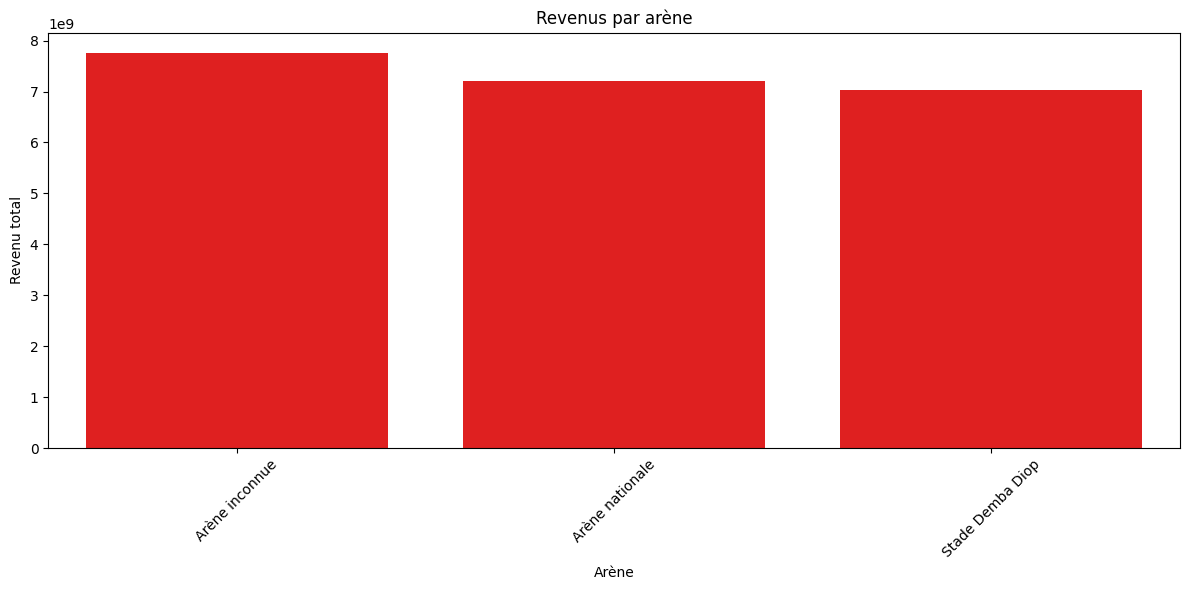

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12,6))
sns.barplot(data=pdf_arena, x="arena", y="revenu_total", color="red")
plt.xticks(rotation=45)
plt.title("Revenus par arène")
plt.xlabel("Arène")
plt.ylabel("Revenu total")
plt.tight_layout()
plt.savefig("graph3_arena.png", dpi=300)
plt.show()

In [60]:
from google.colab import files
files.download("graph3_arena.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


L’analyse des revenus par arène montre que la catégorie “Arène inconnue” génère les revenus les plus élevés dans le dataset. Toutefois, cette catégorie ne correspond pas nécessairement à une arène spécifique, mais peut regrouper des combats locaux ou traditionnels.

Dans le contexte sénégalais, ces combats peuvent inclure des formes de rémunération non monétaires (maisons, bétail, véhicules, etc.), ce qui peut influencer le niveau de revenus observé. Par conséquent, cette catégorie mélange plusieurs types d’événements et doit être interprétée avec prudence.

Ainsi, bien que les arènes officielles comme l’Arène nationale et le Stade Demba Diop restent des lieux majeurs du lamb professionnel, la présence d’une catégorie “inconnue” met en évidence une limite du dataset et souligne la nécessité de mieux distinguer les types de combats pour une analyse plus précise.

Partie 4: Ventes de tickets

Le revenu moyen par tranche de ticket



In [66]:
from pyspark.sql.functions import when

df_bins = df_clean.withColumn(
    "ticket_range",
    when(df_clean.tickets_sold < 5000, "0-5k")
    .when((df_clean.tickets_sold >= 5000) & (df_clean.tickets_sold < 10000), "5k-10k")
    .when((df_clean.tickets_sold >= 10000) & (df_clean.tickets_sold < 15000), "10k-15k")
    .otherwise("15k+")
)

df_bins.select("tickets_sold", "ticket_range", "total_revenue").show(10, truncate=False)

+------------+------------+-------------+
|tickets_sold|ticket_range|total_revenue|
+------------+------------+-------------+
|14087       |10k-15k     |3536646.0    |
|6242        |5k-10k      |1.2399762E7  |
|19128       |15k+        |596309.0     |
|8892        |5k-10k      |1.8230034E7  |
|4224        |0-5k        |5.0935907E7  |
|19173       |15k+        |3.9507978E7  |
|9924        |5k-10k      |4.098975E7   |
|8457        |5k-10k      |2370018.0    |
|18036       |15k+        |3.2416174E7  |
|5170        |5k-10k      |2109271.0    |
+------------+------------+-------------+
only showing top 10 rows


Calcul du revenu moyen

In [67]:
from pyspark.sql.functions import avg

revenue_by_range = df_bins.groupBy("ticket_range") \
    .agg(avg("total_revenue").alias("revenu_moyen")) \
    .orderBy("ticket_range")

revenue_by_range.show(truncate=False)

+------------+--------------------+
|ticket_range|revenu_moyen        |
+------------+--------------------+
|0-5k        |1.0581529352941176E7|
|10k-15k     |1.1477568922787193E7|
|15k+        |9888951.158396946   |
|5k-10k      |1.2004774805168986E7|
+------------+--------------------+



In [68]:
pdf_range = revenue_by_range.toPandas()
pdf_range

,ticket_range,revenu_moyen
0,0-5k,1.058153e+07
1,10k-15k,1.147757e+07
2,15k+,9.888951e+06
3,5k-10k,1.200477e+07


Scatter plot

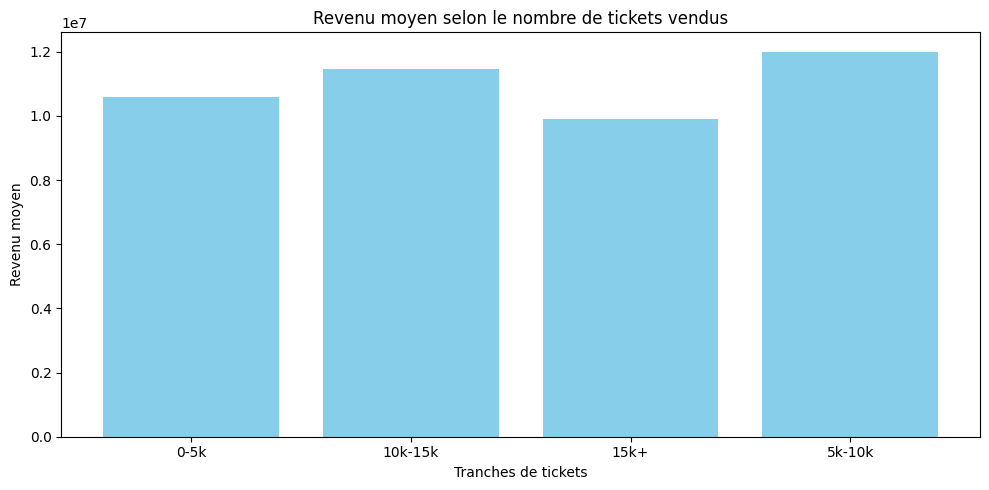

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.bar(pdf_range["ticket_range"], pdf_range["revenu_moyen"], color="skyblue")

plt.title("Revenu moyen selon le nombre de tickets vendus")
plt.xlabel("Tranches de tickets")
plt.ylabel("Revenu moyen")
plt.tight_layout()

plt.savefig("graph_revenu_tickets.png", dpi=300, bbox_inches="tight")
plt.show()

In [74]:
from google.colab import files
files.download("graph_revenu_tickets.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


On observe que le revenu moyen augmente globalement avec le nombre de tickets vendus.  

Les combats ayant une forte affluence (plus de 10 000 tickets) génèrent en moyenne des revenus plus élevés que ceux avec une faible affluence.  

Cependant, certaines variations existent, ce qui suggère que d’autres facteurs, comme les sponsors ou la popularité des lutteurs, influencent également les revenus.